# CtreeX Quick Start

## Simple explanations

Counterfactual explanations of a scikit-learn decision tree trained on a small synthetic loan data set with one numerical (income) and one categorical (housing, one-hot encoded) feature.

In [1]:
import numpy as np
from sklearn.tree import DecisionTreeClassifier
from ctreex import Feature, FeatureSpec, TreeCounterfactualExplainer

rng = np.random.RandomState(42)
income = rng.randint(500, 5000, 400)
housing = rng.choice(['rent', 'own', 'council'], 400)
X = np.column_stack([income] + [(housing == h).astype(float) for h in ('rent', 'own', 'council')])
y = np.where((income > 2500) | ((income > 1500) & (housing == 'own')), 'accepted', 'declined')
clf = DecisionTreeClassifier(max_depth=4, random_state=0).fit(X, y)

A `FeatureSpec` maps the columns of the one-hot encoded data to the features;
`Feature` adds display names and names of the categories.

In [2]:
spec = FeatureSpec(
    [('income', None),
     ('housing', 'rent'),
     ('housing', 'own'),
     ('housing', 'council')],
    features=[Feature('income',  'numerical',   display_name='monthly income'),
              Feature('housing', 'categorical', display_name='housing',
                      value_names={'rent': 'renting',
                                   'own': 'owning a house',
                                   'council': 'council housing'})])
explainer = TreeCounterfactualExplainer(clf, spec)
explainer.tree

TreeStructure(n_nodes=7, n_leaves=4, n_features=4, classes=['accepted', 'declined'])

In [3]:
x = spec.encode({'income': 1800, 'housing': 'rent'})
explanation = explainer.explain_instance(x)
print('prediction:', explanation.prediction, '| leaf:', explanation.leaf)
for distance, counterfactual in explanation.ranked():
    print(distance, explainer.describe({0: counterfactual})[0])

prediction: declined | leaf: 2
1 {'housing': {'is': ['renting'], 'wannabe': ['owning a house']}}
1 {'monthly income': {'is': [1800], 'wannabe': ['more than 2512.5']}}


Tree leaves grouped by their distance (the number of features that must change);
the `target` leaves (by default, of another class) yield the counterfactuals:

In [4]:
explanation.support

{0: {'target': [], 'non_target': [2]},
 2: {'target': [], 'non_target': [4]},
 1: {'target': [5, 6], 'non_target': []}}

Counterfactuals that must not change a feature (`excluded`) or may change only selected features (`included`):

In [5]:
for distance, counterfactual in explainer.explain_instance(x, excluded=['income']).ranked():
    print(distance, explainer.describe({0: counterfactual})[0])

1 {'housing': {'is': ['renting'], 'wannabe': ['owning a house']}}


## Meta-features and leaf-to-leaf distances

Every leaf is described by the meta-features derived from the split conditions:
- `1` when the meta-feature is implied by the path
- `-1` when it is contradicted and
- `0` when it is unconstrained.

In [6]:
lmf = explainer.leaf_meta_features
print([m.name for m in lmf.meta_features])
print(lmf.leaf_ids, lmf.leaf_classes)
print(lmf.matrix)

['income<=1501.5', '1501.5<income<=2512.5', '2512.5<income', 'housing_rent', 'housing_own', 'housing_council']
[2 4 5 6] ['declined' 'declined' 'accepted' 'accepted']
[[ 1  1 -1  0 -1  0]
 [ 1 -1 -1 -1  1 -1]
 [-1  1 -1 -1  1 -1]
 [-1 -1  1  0  0  0]]


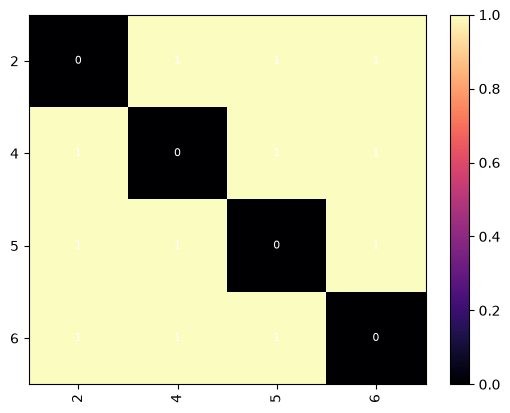

In [7]:
from ctreex.plot import metric_heat_map
matrix, leaf_ids, leaf_classes = explainer.leaf_distance_matrix()
metric_heat_map(matrix, leaf_ids, leaf_classes, annot=True, xtick=True, ytick=True);

## Saving trees

Trees are stored as JSON independently of the scikit-learn version.

In [8]:
import tempfile, os
from ctreex import TreeStructure, load_tree
path = os.path.join(tempfile.mkdtemp(), 'tree.json')
TreeStructure.from_sklearn(clf, feature_names=spec.column_names).to_json(path)
load_tree(path).predict(X[:5])

array(['declined', 'accepted', 'accepted', 'declined', 'accepted'],
      dtype='<U8')